<a href="https://colab.research.google.com/github/caltrop1/fitfactor-AI/blob/main/Food_Recognizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q rfdetr
%pip install -q supervision

In [2]:
from sys import version

import torch
import rfdetr
import supervision as sv
import importlib.metadata

rfdetr_version = importlib.metadata.version("rfdetr")
print("PyTorch:", torch.__version__)
print("RF-DETR:", rfdetr_version)
print("Supervision:", sv.__version__)

print("\nCUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


PyTorch: 2.14.1+cu130
RF-DETR: 1.12.0
Supervision: 0.31.6

CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [3]:
from rfdetr import RFDETRNano

model = RFDETRNano()
print("Succesfully loaded Nano")

[2026-11-11 18:49:38] [INFO] rf-detr - Downloading pretrained weights for /root/.roboflow/models/rf-detr-nano.pth


/root/.roboflow/models/rf-detr-nano.pth:   0%|          | 0.00/349M [00:00<?, ?iB/s]

[2026-11-11 18:49:45] [INFO] rf-detr - MD5 validation successful for /root/.roboflow/models/rf-detr-nano.pth
[2026-11-11 18:49:47] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-nano.pth already exists with correct MD5 hash.
Succesfully loaded Nano


Image dimensions: (401, 620)


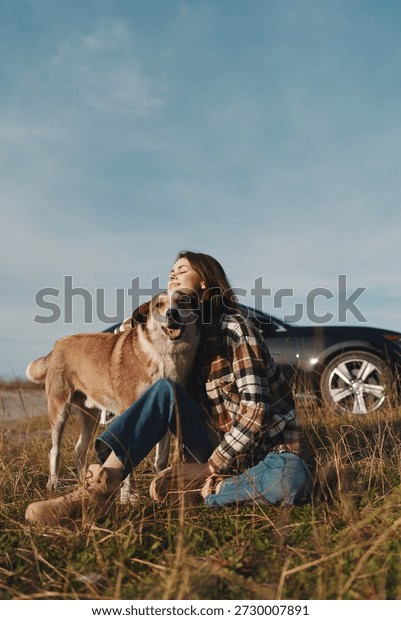

In [4]:
import requests
from PIL import Image
from IPython.display import display

response = requests.get("https://www.shutterstock.com/image-photo/woman-sits-dog-grassy-field-600w-2730007891.jpg")
response.raise_for_status()

with open("Dog.jpg", "wb") as f:
  f.write(response.content)

image = Image.open("Dog.jpg").convert("RGB")
print("Image dimensions:", image.size)
display(image)

In [5]:
import time

start_time = time.time()

detections = model.predict("Dog.jpg", threshold = 0.5)

end_time = time.time()

print("Detection Succesful!")
print("Processing time: ", end_time - start_time)
print("\nDetected objects:", len(detections))

for detection in detections:
  print(detection, "\n")

[2026-11-11 18:54:21] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. Create predictor = native_model.inference(...) and use predictor.predict(...). For a checkpoint, first load native_model = RFDETR.from_checkpoint(...).


Detection Succesful!
Processing time:  6.1933274269104

Detected objects: 3
(array([ 30.912443, 250.70166 , 315.62875 , 523.2437  ], dtype=float32), None, np.float32(0.8851331), np.int64(1), None, {'source_shape': array([620, 401]), 'class_name': 'person'}) 

(array([ 25.378746, 287.88205 , 202.68333 , 496.35193 ], dtype=float32), None, np.float32(0.8658778), np.int64(18), None, {'source_shape': array([620, 401]), 'class_name': 'dog'}) 

(array([256.3617 , 314.48413, 400.72778, 419.1102 ], dtype=float32), None, np.float32(0.791778), np.int64(3), None, {'source_shape': array([620, 401]), 'class_name': 'car'}) 



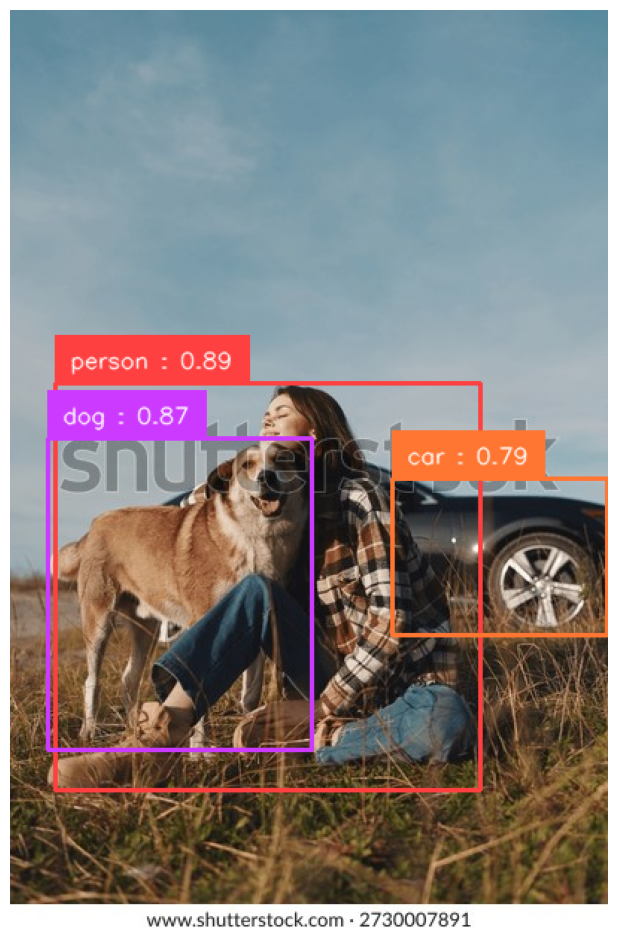

In [6]:
import supervision as sv
import cv2
from rfdetr.assets.coco_classes import COCO_CLASSES

labels = [f"{COCO_CLASSES[class_id]} : {confidence:.2f}"
            for class_id, confidence in zip(detections.class_id, detections.confidence)]

image = cv2.imread("Dog.jpg")
box_annotator = sv.BoxAnnotator()
label_annotator = sv.LabelAnnotator()

annotated_image = image.copy()
annotated_image = box_annotator.annotate(scene=annotated_image, detections=detections)
annotated_image = label_annotator.annotate(scene=annotated_image, detections=detections, labels=labels)
sv.plot_image(annotated_image)


In [9]:
from google.colab import files
uploaded = files.upload()
image_filename = next(iter(uploaded))
print("Uploaded:", image_filename)

Saving Salad.jpeg to Salad.jpeg
Uploaded: Salad.jpeg


[51 56 47]
[0.9490463  0.37771448 0.3290694 ]


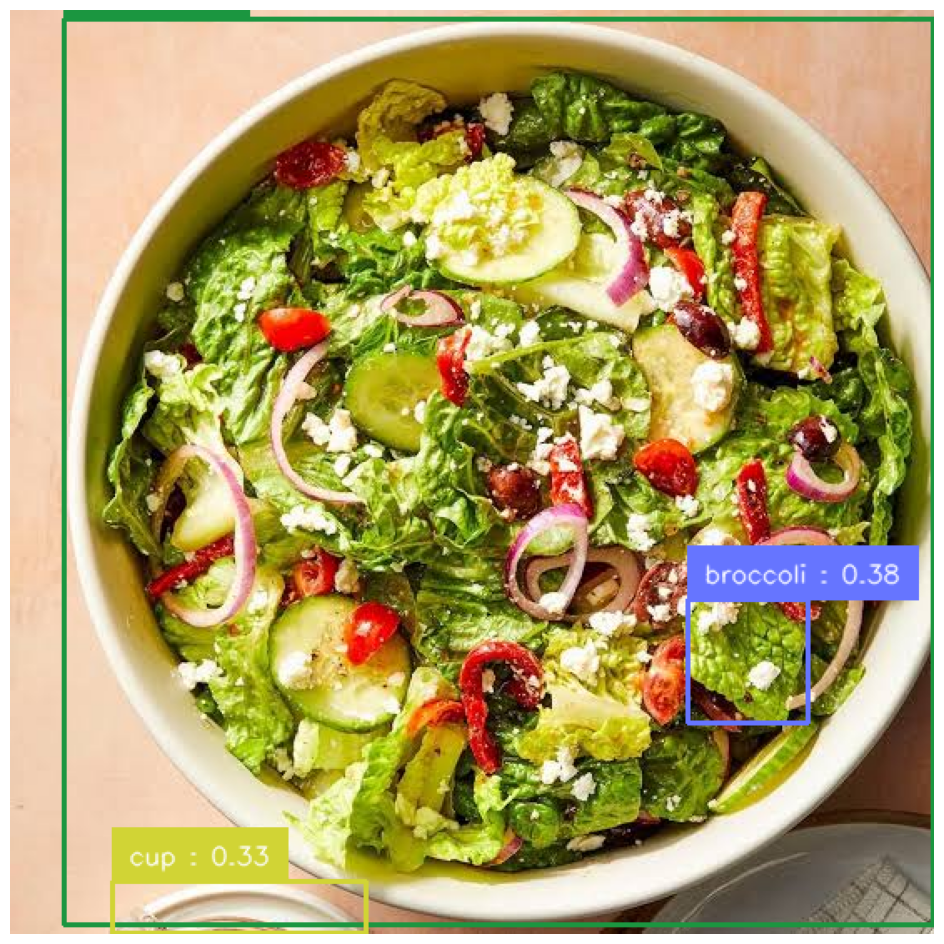

In [30]:
from PIL import Image
from pycocotools.coco import COCO
import cv2
import supervision as sv
image = Image.open(image_filename).convert("RGB")

detections = model.predict(image, threshold = 0.3)
print(detections.class_id)
print(detections.confidence)
#xyxy, confidence, class_id, mask, tracker_id, detections.data
#labels = [COCO_CLASSES[detections[i].class_id : detections[i].confidence]

labels = [ f"{COCO_CLASSES[class_id]} : {confidence:.2f}"
    for class_id, confidence in zip(detections.class_id, detections.confidence)]

img = cv2.imread(image_filename)
box_annotator = sv.BoxAnnotator()
label_annotator = sv.LabelAnnotator()

annotated_image = box_annotator.annotate(scene=img, detections=detections)
annotated_image = label_annotator.annotate(scene=img, detections=detections, labels=labels)
sv.plot_image(annotated_image)